# Education 360° — Financial Analytics
Analyze billed fees, collections, outstanding balances, payment status, and payment modes.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

PROJECT_PATH = Path.cwd().parent if Path.cwd().name.lower() == "python" else Path.cwd()
DATA_PATH = PROJECT_PATH / "Dataset"

# Accommodate the source filename spelling found in the project.
FILE_CANDIDATES = {
    "admissions": ["admissions.csv"],
    "branches dim": ["braches dim.csv"],
    "calls": ["calls.csv"],
    "courses dim": ["courses dim.csv"],
    "employees": ["employees.csv"],
    "fees": ["fees.csv"],
    "leads": ["leads.csv"],
    "marketing": ["marketing.csv"],
    "placements": ["placements.csv"],
    "students dim": ["students dim.csv"]
}


def load_table(table_name):
    candidates = FILE_CANDIDATES[table_name]
    for filename in candidates:
        path = DATA_PATH / filename
        if path.exists():
            return pd.read_csv(path)
    raise FileNotFoundError(
        f"Could not find {table_name}. Tried: {candidates}. "
        f"Expected dataset folder: {DATA_PATH}"
    )

datasets = {}
for table in FILE_CANDIDATES:
    try:
        datasets[table] = load_table(table)
        print(f"{table:15} {datasets[table].shape}")
    except FileNotFoundError as exc:
        print(exc)

admissions      (2000, 10)
Could not find branches dim. Tried: ['branches_dim.csv', 'braches_dim.csv']. Expected dataset folder: c:\Users\aadit\Desktop\Data_Analyst_Portfolio\Project 03 — Academy Business Analytics\Dataset
calls           (18226, 7)
Could not find courses dim. Tried: ['courses_dim.csv']. Expected dataset folder: c:\Users\aadit\Desktop\Data_Analyst_Portfolio\Project 03 — Academy Business Analytics\Dataset
Could not find date table. Tried: ['DateTable.csv', 'date_table.csv']. Expected dataset folder: c:\Users\aadit\Desktop\Data_Analyst_Portfolio\Project 03 — Academy Business Analytics\Dataset
employees       (30, 5)
fees            (2000, 8)
leads           (2000, 6)
marketing       (150, 8)
placements      (2000, 7)
Could not find students dim. Tried: ['students_dim.csv']. Expected dataset folder: c:\Users\aadit\Desktop\Data_Analyst_Portfolio\Project 03 — Academy Business Analytics\Dataset


In [2]:
fees = datasets["fees"].copy()
for col in ["total fee","paid fee","remaining fee"]:
    if col in fees:
        fees[col] = pd.to_numeric(fees[col], errors="coerce")
display(fees.head())

,payment id,student id,total fee,paid fee,remaining fee,payment status,payment mode,collection%
0,P00004,S00004,40000,40000,0,Completed,Cash,1.00
1,P00018,S00018,40000,40000,0,Completed,Net Banking,1.00
2,P00022,S00022,40000,40000,0,Completed,Net Banking,1.00
3,P00026,S00026,40000,40000,0,Completed,UPI,1.00
4,P00036,S00036,40000,40000,0,Completed,Card,1.00


## Core financial KPIs

In [3]:
billed = fees["total fee"].sum()
collected = fees["paid fee"].sum()
remaining = fees["remaining fee"].sum()
efficiency = collected / billed * 100 if billed else np.nan
print(f"Total billed: ₹{billed:,.2f}")
print(f"Total collected: ₹{collected:,.2f}")
print(f"Outstanding fees: ₹{remaining:,.2f}")
print(f"Collection efficiency: {efficiency:.2f}%")
print("Reconciliation (billed - collected - remaining):", billed-collected-remaining)

Total billed: ₹66,065,000.00
Total collected: ₹52,491,750.00
Outstanding fees: ₹13,573,250.00
Collection efficiency: 79.45%
Reconciliation (billed - collected - remaining): 0


## Payment status

,Records
Payment Status,
Pending,1465
Completed,535


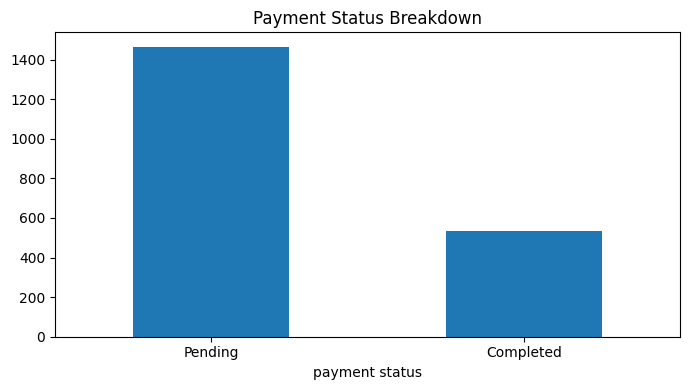

In [4]:
if "payment status" in fees:
    display(fees["payment status"].value_counts(dropna=False).rename_axis("Payment Status").to_frame("Records"))
    fees["payment status"].value_counts().plot(kind="bar", figsize=(7,4), title="Payment Status Breakdown")
    plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## Payment mode

,payment mode,Payments,Collected,Outstanding
0,Card,497,13105000,3310000
1,Cash,530,14098000,3607000
2,Net Banking,489,12750500,3344500
3,UPI,484,12538250,3311750


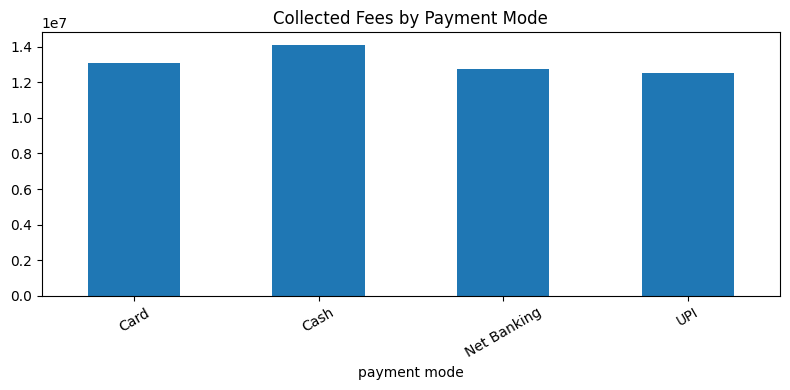

In [5]:
if "payment mode" in fees:
    mode_summary = fees.groupby("payment mode").agg(
        Payments=("payment id","nunique"),
        Collected=("paid fee","sum"),
        Outstanding=("remaining fee","sum")
    ).reset_index()
    display(mode_summary)
    mode_summary.plot(x="payment mode", y="Collected", kind="bar", figsize=(8,4),
                      title="Collected Fees by Payment Mode", legend=False)
    plt.xticks(rotation=30); plt.tight_layout(); plt.show()

## Fees by course

In [6]:
students = datasets["students dim"][["student id","course id"]].drop_duplicates()
courses = datasets["courses dim"]
fee_course = fees.merge(students, on="student id", how="left")
if {"course_id","course_name"}.issubset(courses.columns):
    fee_course = fee_course.merge(courses[["course_id","course_name"]],
                                  left_on="course id", right_on="course_id", how="left")
if "course_name" in fee_course:
    display(fee_course.groupby("course_name").agg(
        Billed=("total fee","sum"), Collected=("paid fee","sum"),
        Remaining=("remaining fee","sum")
    ).reset_index())

KeyError: 'students dim'

## Validation
Check that billed = collected + remaining (within rounding tolerance). Avoid calling the average total fee 'average revenue' unless that definition is intended.